# Order Execution Simulator — SET50 hourly bars

Flow: **market data → signal → pre-trade check → execution (MARKET vs TWAP) → execution-quality metrics**.
All logic lives in `src/`; this notebook only calls it and plots. Config: `src/constants.py`.

Data: every `SET50_*.csv` in this folder (long format, hourly OHLC + traded value/volume). If none is present the notebook falls back to synthetic GBM prices.

Orders are decided at the close of bar *t* and start filling at the close of bar *t+1*. The participation cap and market impact use each bar's actual `TRADING_VALUE`.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src import constants as C, data_loader, signals, simulator, metrics
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)

files = data_loader.data_files()
md = data_loader.load_csv(files) if files else data_loader.synthetic_prices()
prices, info = md.close, md.info
print(", ".join(info["files"]), "|", prices.shape, "|", info["start"], "→", info["end"],
      "|", data_loader.bars_per_day(prices.index), "bars/day")
prices.tail()

SET50_2023.csv, SET50_2024.csv, SET50_2025.csv, SET50_2026.csv | (6576, 10) | 2023-01-03 10:00:00 → 2026-11-19 17:00:00 | 7 bars/day


,KBANK,CPALL,ADVANC,PTTEP,AOT,BBL,SCB,PTT,KTB,BDMS
datetime,,,,,,,,,,
2026-11-19 12:00:00,251.0,49.4,336.0,143.5,60.75,181.5,152.0,37.4,42.4,20.10
2026-11-19 13:00:00,251.0,49.4,337.0,143.5,61.00,181.5,152.5,37.5,42.4,20.20
2026-11-19 15:00:00,250.0,49.5,336.0,144.0,61.50,181.5,152.5,37.5,42.3,20.35
2026-11-19 16:00:00,250.0,49.6,336.0,144.0,61.50,182.0,152.0,37.6,42.3,20.40
2026-11-19 17:00:00,250.0,49.8,338.0,143.5,61.50,182.0,152.5,37.4,42.4,20.45


## 1. Signal — SMA crossover + RSI filter
BUY: SMA_fast crossed above SMA_slow within the last `BUY_CONFIRM_BARS` bars, still above, RSI < 70 (once per cross).
SELL: SMA_fast crosses below SMA_slow, or RSI crosses up through 80.
Size: Δw = clip(K × |Close − SMA_slow| / ATR, 1%, 5%).

signal  BUY  SELL
ticker           
ADVANC  136   152
AOT     133   150
BBL     140   165
BDMS    141   151
CPALL   118   134
KBANK   124   149
KTB     136   147
PTT     137   142
PTTEP   119   129
SCB     134   150


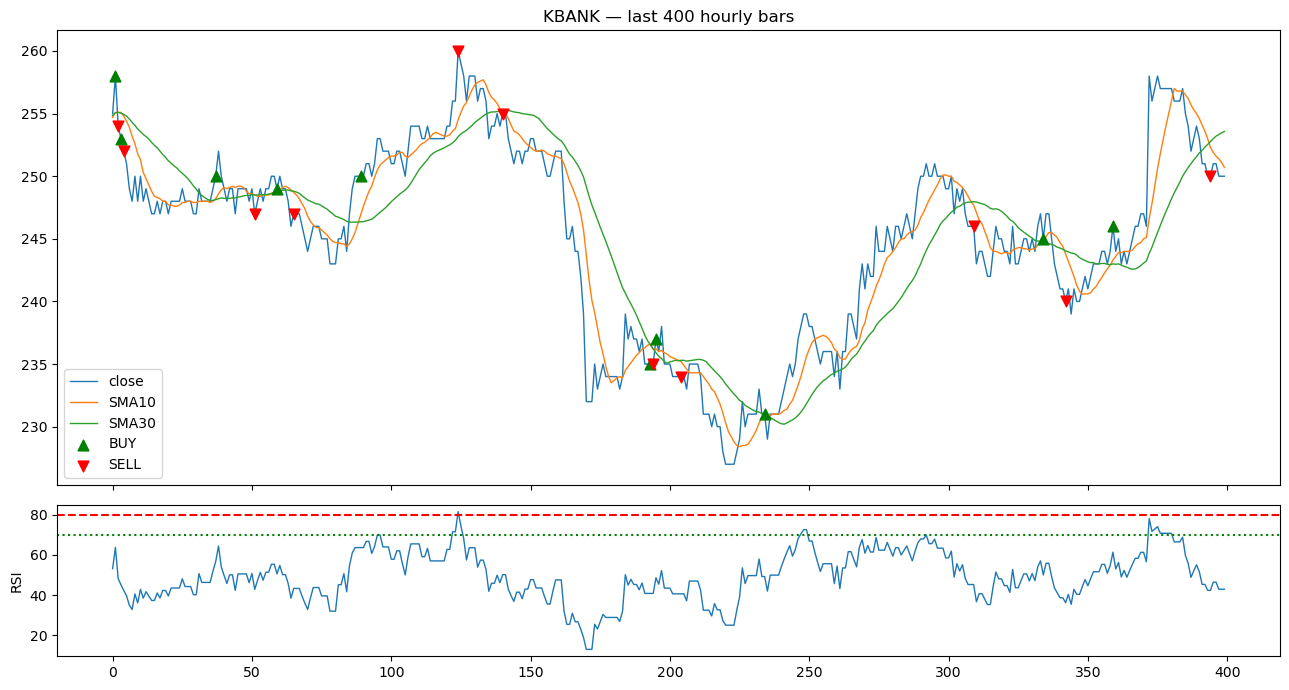

In [2]:
sig = signals.compute_all(prices)
events = signals.signals_long(sig, only_events=True)
print(events.groupby(["ticker", "signal"]).size().unstack(fill_value=0))

t = prices.columns[0]
s = sig[t].iloc[-400:]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
x = np.arange(len(s))
a1.plot(x, s["close"], lw=1, label="close"); a1.plot(x, s["sma_fast"], lw=1, label=f"SMA{C.SMA_FAST}")
a1.plot(x, s["sma_slow"], lw=1, label=f"SMA{C.SMA_SLOW}")
for code_, m, c in [(signals.BUY, "^", "green"), (signals.SELL, "v", "red")]:
    k = s["signal_code"].to_numpy() == code_
    a1.scatter(x[k], s["close"].to_numpy()[k], marker=m, color=c, s=60, zorder=3, label=signals.LABEL[code_])
a1.set_title(f"{t} — last 400 hourly bars"); a1.legend()
a2.plot(x, s["rsi"], lw=1); a2.axhline(C.RSI_SELL, ls="--", c="r"); a2.axhline(C.RSI_BUY_MAX, ls=":", c="g")
a2.set_ylabel("RSI"); plt.tight_layout(); plt.show()

## 2–3. Pre-trade + execution
Each strategy runs its own portfolio on the same prices and signals. MARKET = 1 slice (bar t+1), TWAP = 5 hourly slices (bars t+1 … t+5).

In [3]:
results = simulator.run_all(md, sig)
orders, comp = metrics.comparison(results, md)
log = pd.concat([pd.DataFrame(r["pretrade_log"]) for r in results.values()], ignore_index=True)
log.groupby(["strategy", "check", "action"]).size().unstack(fill_value=0)

action                  ADJUST  REJECT
strategy check                        
MARKET   CASH               18       5
         MIN_NOTIONAL        0      56
         WEIGHT_BOUNDS     374       0
         ZERO_LOT            0      35
TWAP     ACTIVE_ORDER        0     270
         CASH                5       5
         MIN_NOTIONAL        0      57
         WEIGHT_BOUNDS     366       0
         ZERO_LOT            0      43

## 4. Execution comparison

In [4]:
from src.excel_export import COMPARISON_LABELS
view = comp.loc[[k for k in COMPARISON_LABELS if k in comp.index]]
view.index = [COMPARISON_LABELS[k][0] for k in view.index]
view

,MARKET,TWAP
Slices per order,1,5
Parent orders,2692,2420
of which BUY,1313,1179
of which SELL,1379,1241
Pre-trade rejects,96,375
Pre-trade adjustments,392,371
Traded value (THB),482994146.406962,444302747.829345
Fill rate — avg per order,0.995519,0.994268
Fill rate — value weighted,0.996596,0.996032
"Implementation shortfall (bps, value wtd)",38.358638,39.322922


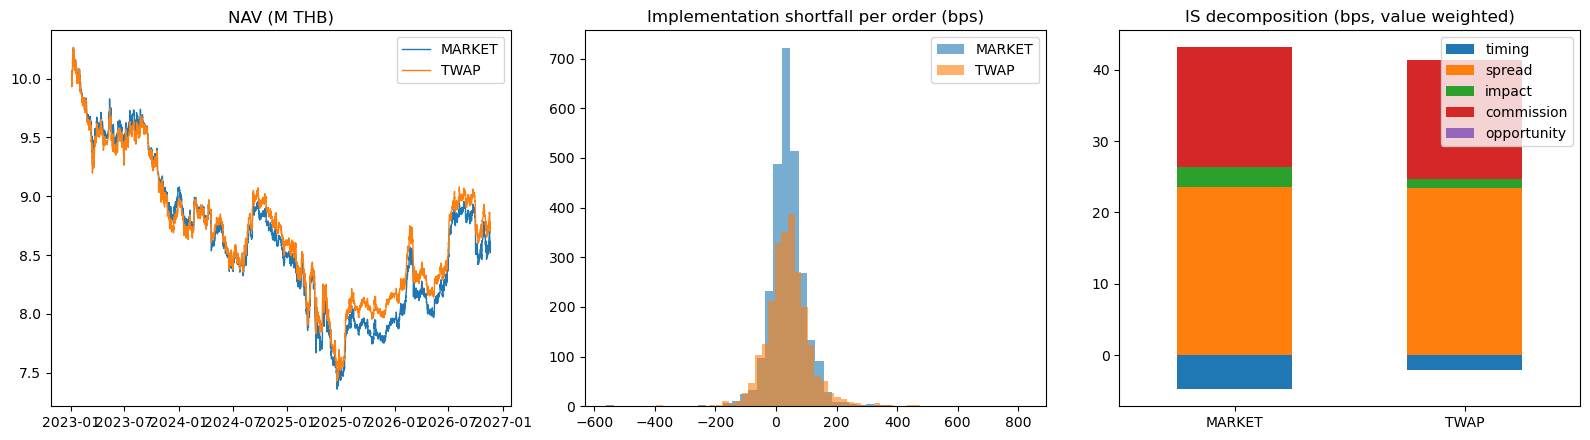

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for name, r in results.items():
    axes[0].plot(r["nav"].index, r["nav"]["nav"] / 1e6, lw=1, label=name)
axes[0].set_title("NAV (M THB)"); axes[0].legend()

for name in results:
    axes[1].hist(orders.loc[orders.strategy == name, "is_bps"], bins=50, alpha=.6, label=name)
axes[1].set_title("Implementation shortfall per order (bps)"); axes[1].legend()

comps = ["timing", "spread", "impact", "commission", "opportunity"]
bars = comp.loc[[f"{c}_bps_value_wtd" for c in comps]]; bars.index = comps
bars.T.plot(kind="bar", stacked=True, ax=axes[2], rot=0)
axes[2].set_title("IS decomposition (bps, value weighted)")
plt.tight_layout(); plt.show()

In [6]:
cols = ["strategy", "ticker", "side", "reason", "arrival_time", "arrival_price", "qty", "fill_rate",
        "avg_fill_price", "twap_benchmark", "vwap_benchmark", "vs_vwap_bps", "is_bps", "timing_bps", "spread_bps", "impact_bps", "commission_bps"]
orders.sort_values("paper_notional", ascending=False)[cols].head(10)

,strategy,ticker,side,reason,arrival_time,arrival_price,qty,fill_rate,avg_fill_price,twap_benchmark,vwap_benchmark,vs_vwap_bps,is_bps,timing_bps,spread_bps,impact_bps,commission_bps
2724,TWAP,BBL,SELL,SIGNAL_SELL,2023-01-27 11:00:00,161.50,3100,1.0,162.124387,162.40,162.233824,6.745630,-21.797787,-54.928593,15.479876,0.786981,16.863948
37,MARKET,BBL,SELL,SIGNAL_SELL,2023-01-27 11:00:00,161.50,3100,1.0,161.725244,162.40,162.233824,31.348573,2.875428,-30.959752,15.479876,1.532874,16.822430
2730,TWAP,SCB,SELL,SIGNAL_SELL,2023-01-31 12:00:00,105.50,4700,1.0,104.343450,104.60,104.489380,13.966010,126.240464,84.703035,23.696682,1.225907,16.614840
43,MARKET,SCB,SELL,SIGNAL_SELL,2023-01-31 12:00:00,105.50,4700,1.0,104.229866,104.60,104.489380,24.836394,136.988632,94.786730,23.696682,1.908466,16.596754
2,MARKET,CPALL,SELL,SIGNAL_SELL,2023-01-11 13:00:00,68.75,7200,1.0,68.603160,68.55,68.482218,-17.660338,38.121656,0.000000,18.181818,3.176718,16.763120
2694,TWAP,CPALL,SELL,SIGNAL_SELL,2023-01-11 13:00:00,68.75,7200,1.0,68.416332,68.55,68.482218,9.620937,65.251019,28.787879,18.181818,1.563854,16.717468
2729,TWAP,AOT,SELL,SIGNAL_SELL,2023-01-31 11:00:00,74.50,6500,1.0,74.268956,74.40,74.373342,14.035446,47.759520,13.422819,16.778523,0.811276,16.746902
42,MARKET,AOT,SELL,SIGNAL_SELL,2023-01-31 11:00:00,74.50,6500,1.0,74.359016,74.40,74.373342,1.926272,35.691241,0.000000,16.778523,2.145508,16.767210
447,MARKET,SCB,SELL,SIGNAL_SELL,2023-08-23 16:00:00,118.00,4100,1.0,117.231124,117.50,117.430385,16.968474,81.848552,42.372881,21.186441,1.599690,16.689539
452,MARKET,PTTEP,BUY,SIGNAL_BUY,2023-08-28 11:00:00,161.00,3000,1.0,160.799481,160.20,160.113971,42.813847,4.323479,-31.055901,15.527950,3.073352,16.778078


### Reading the result
* **MARKET** fills everything one bar after the decision → one bar of timing risk, all impact up-front.
* **TWAP** spreads the order over 5 bars → less impact per child but more price drift while working, and it
  skips new signals for a ticker while its order is still open (`ACTIVE_ORDER` rejects), so the two strategies
  end up with different order sets.
* With a 10 M THB portfolio each child is a tiny share of the bar's traded value, so **half-spread (1 tick,
  an assumption — the data has no bid/ask) and commission dominate**; impact is only a few bps.
* `vs VWAP` compares the average fill with the market VWAP of bars t+1 … t+5 (from `TRADING_VALUE / TRADING_VOLUME`).